# Read Data

In [2]:
import pandas as pd
import numpy as np

pd.set_option("display.width", 120)

# A sample first. Reading all 3M rows takes ~40 seconds; 200k is enough to look around.
SAMPLE = 200_000
df = pd.read_csv("../data/raw/tx.csv", nrows=SAMPLE)
df.shape

(200000, 11)

# Explore

In [4]:
df.head(3)

,Timestamp,From Bank,From Account,To Bank,To Account,Amount Received,Receiving Currency,Amount Paid,Payment Currency,Payment Format,Is Laundering
0,2025-01-01 00:00:29,3295718,A009852,2657408,A010012,4.40,CHF,8.06,AUD,Mobile,0
1,2025-01-01 00:00:40,3186407,A007397,3295718,A010077,58.45,CNY,58.51,CNY,Cash,0
2,2025-01-01 00:01:22,3186407,A007852,2793615,A003712,5576.27,CNY,5581.85,CNY,Mobile,0


In [16]:
df.dtypes

Timestamp             datetime64[ns]
From Bank                      int64
From Account                  object
To Bank                        int64
To Account                    object
Amount Received              float64
Receiving Currency            object
Amount Paid                  float64
Payment Currency              object
Payment Format                object
Is Laundering                  int64
dtype: object

## Missing Data

In [6]:
df.isna().sum()

Timestamp             0
From Bank             0
From Account          0
To Bank               0
To Account            0
Amount Received       0
Receiving Currency    0
Amount Paid           0
Payment Currency      0
Payment Format        0
Is Laundering         0
dtype: int64

## Positive and Negative Laundry 

In [18]:
counts = df["Is Laundering"].value_counts()
rate = df["Is Laundering"].mean()

print(counts)
print(f"\npositive rate: {rate:.5f}  ({100*rate:.3f}%)")
print(f"all transactions N: {len(df)} ")


Is Laundering
0    199852
1       148
Name: count, dtype: int64

positive rate: 0.00074  (0.074%)
all transactions N: 200000 


## Collection period

Needed because the train/test split must be by time, not random. A random split
would let the model see the future.

In [20]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print("from:", df["Timestamp"].min())
print("to:  ", df["Timestamp"].max())
print("_______\n", df["Timestamp"].max() - df["Timestamp"].min())

print("#######\n Sorted?", df["Timestamp"].is_monotonic_increasing)


from: 2025-01-01 00:00:29
to:   2025-01-23 11:28:44
_______
 22 days 11:28:15
#######
 Sorted? True
rows sharing a timestamp with another row: 6.5%


## Duplicated?

In [23]:

dup= df["Timestamp"].duplicated().mean()
print(f"Duplicated timestamps: {100*dup:.1f}%")

Duplicated timestamps: 6.5%


## Account and Transaction Stat Per Sender


In [9]:
senders = df["From Account"].nunique()
receivers = df["To Account"].nunique()
per_account = df["From Account"].value_counts()

print(f"distinct senders  : {senders:,}")
print(f"distinct receivers: {receivers:,}")
print(f"\ntransactions per sender, in this sample:")
print(per_account.describe())

distinct senders  : 11,897
distinct receivers: 11,679

transactions per sender, in this sample:
count    11897.000000
mean        16.810961
std          8.978032
min          1.000000
25%         10.000000
50%         17.000000
75%         23.000000
max         64.000000
Name: count, dtype: float64


## Amounts

Log scale, because money is spread over orders of magnitude.

In [10]:
df["Amount Paid"].describe()

count    2.000000e+05
mean     1.541915e+03
std      1.502626e+04
min      3.000000e-02
25%      3.242000e+01
50%      7.041000e+01
75%      1.456600e+02
max      2.864231e+06
Name: Amount Paid, dtype: float64

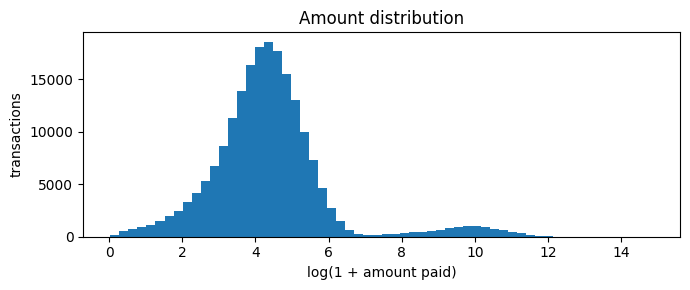

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 3))
plt.hist(np.log1p(df["Amount Paid"]), bins=60)
plt.xlabel("log(1 + amount paid)")
plt.ylabel("transactions")
plt.title("Amount distribution")
plt.tight_layout()
plt.show()

# Positive laundry patterns

In [25]:
long = pd.concat([
    pd.DataFrame({"row": df.index, "account": df["From Account"], "role": "sender"}),
    pd.DataFrame({"row": df.index, "account": df["To Account"], "role": "receiver"}),
]).sort_values("row", kind="stable")

long["before"] = long.groupby("account").cumcount()
long["after"] = long.groupby("account")["row"].transform("size") - long["before"] - 1

for role in ["sender", "receiver"]:
    part = long[long["role"] == role].set_index("row")
    df[f"{role}_before"] = part["before"]
    df[f"{role}_after"] = part["after"]

cols = ["sender_before", "sender_after", "receiver_before", "receiver_after", "Amount Paid"]
summary = df.groupby("Is Laundering")[cols].agg(["mean", "std", "median"]).T
summary.columns = ["Normal Transactions", "Laundering Transactions"]
summary.round(2)

Normal Transactions  Laundering Transactions
sender_before   mean                  12.72                    50.94
                std                   10.19                   146.12
                median                11.00                     2.00
sender_after    mean                  12.75                    33.57
                std                    9.89                    99.68
                median                11.00                     2.00
receiver_before mean                 269.76                    42.51
                std                  256.31                   107.44
                median               214.00                     2.00
receiver_after  mean                 269.73                    66.39
                std                  256.34                   168.66
                median               214.00                     2.00
Amount Paid     mean                1541.99                  1437.02
                std                15029.95                  8732.47
                median                70.42                    43.22

## Trap hunt

Compare every numeric column between the two classes. If a column is constant for
one class, it is telling you how the file was generated rather than anything about
laundering. A model will find it, score well, and be useless on real data.

In [13]:
# Same idea for the categorical columns: does one class only ever take one value?
for col in ["Receiving Currency", "Payment Currency", "Payment Format"]:
    print(f"--- {col} ---")
    print(pd.crosstab(df[col], label, normalize="columns").round(3))
    print()

--- Receiving Currency ---
Is Laundering           0    1
Receiving Currency            
AUD                 0.006  0.0
CAD                 0.006  0.0
CHF                 0.006  0.0
CNY                 0.956  1.0
EUR                 0.006  0.0
GBP                 0.006  0.0
JPY                 0.006  0.0
USD                 0.006  0.0

--- Payment Currency ---
Is Laundering         0    1
Payment Currency            
AUD               0.006  0.0
CAD               0.007  0.0
CHF               0.006  0.0
CNY               0.956  1.0
EUR               0.006  0.0
GBP               0.006  0.0
JPY               0.006  0.0
USD               0.006  0.0

--- Payment Format ---
Is Laundering       0      1
Payment Format              
Card            0.263  0.331
Cash            0.218  0.230
Mobile          0.299  0.230
Transfer        0.220  0.209



## Does the payment amount always equal the received amount?

A gap means a currency conversion happened. Check whether that gap behaves
differently for the two classes.

In [14]:
cross = df["Payment Currency"] != df["Receiving Currency"]

print(f"cross-currency among clean   : {100*cross[label==0].mean():.2f}%")
print(f"cross-currency among illicit : {100*cross[label==1].mean():.2f}%")
print("\nIf these two numbers are very different, the model will lean on it.")
print("Ask whether that reflects the real world before keeping the feature.")

cross-currency among clean   : 5.05%
cross-currency among illicit : 0.00%

If these two numbers are very different, the model will lean on it.
Ask whether that reflects the real world before keeping the feature.


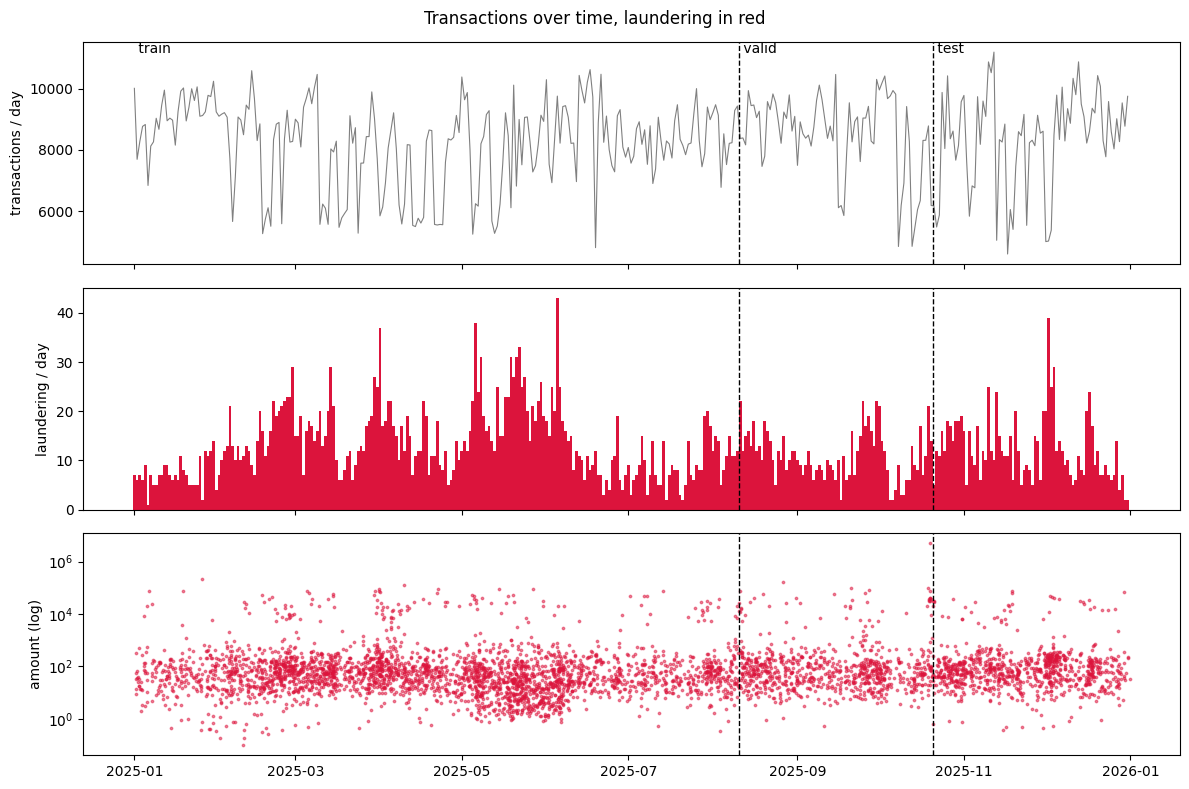

In [26]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("../data/raw/tx.csv", usecols=["Timestamp", "Is Laundering", "Amount Paid"])
data["Timestamp"] = pd.to_datetime(data["Timestamp"])
data = data.sort_values("Timestamp", kind="stable").reset_index(drop=True)

# Where the 60/20/20 split falls in time
n = len(data)
train_end = data["Timestamp"].iloc[int(n * 0.60)]
valid_end = data["Timestamp"].iloc[int(n * 0.80)]

daily = data.set_index("Timestamp").resample("D")["Is Laundering"].agg(["size", "sum"])
laundering = data[data["Is Laundering"] == 1]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# 1. All transactions per day
axes[0].plot(daily.index, daily["size"], color="grey", lw=0.8)
axes[0].set_ylabel("transactions / day")

# 2. Laundering transactions per day
axes[1].bar(daily.index, daily["sum"], color="crimson", width=1)
axes[1].set_ylabel("laundering / day")

# 3. Every laundering transaction as a dot: when it happened, and its amount
axes[2].scatter(laundering["Timestamp"], laundering["Amount Paid"], s=3, color="crimson", alpha=0.5)
axes[2].set_yscale("log")
axes[2].set_ylabel("amount (log)")

# The split boundaries on every panel
for ax in axes:
    ax.axvline(train_end, color="black", ls="--", lw=1)
    ax.axvline(valid_end, color="black", ls="--", lw=1)
axes[0].text(train_end, axes[0].get_ylim()[1], " valid", va="top")
axes[0].text(valid_end, axes[0].get_ylim()[1], " test", va="top")
axes[0].text(data["Timestamp"].iloc[0], axes[0].get_ylim()[1], " train", va="top")

fig.suptitle("Transactions over time, laundering in red")
plt.tight_layout()
plt.show()
